# CodeGraph-RAG / PathPack v0.3

**Исследовательский ноутбук, 1 ноября 2026.** 

Здесь **разделены два типа данных**: реальные агрегаты *со скриншота пользователя* и новые проверки на *4 синтетических задачах*. Значения со скриншота **не являются результатом запуска v0.3**.

Цель v0.3: устранить неустойчивость состава контекста при увеличении бюджета, добавить диагностику пропущенных функций и честную оценку изменений.

In [1]:
from pathlib import Path
import sys, csv, json
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
             if (p / "src" / "codegraph_rag").is_dir()), None)
assert ROOT is not None, "Откройте ноутбук из папки проекта"
sys.path.insert(0, str(ROOT / "src"))
from codegraph_rag.parser import scan_repository
from codegraph_rag.retrieval import make_chunks, select_context
from codegraph_rag.audit import audit_predictions
print("Project:", ROOT)


Project: /mnt/data/CodeGraph-RAG-v0.3


## 1. Исходные агрегаты (SWE-bench Verified, пользовательский скриншот)

Приняты как сообщённые числа. Сырых per-issue predictions здесь нет, статистическую значимость и причины аномалий пока проверить нельзя.

In [2]:
with (ROOT / 'reports' / 'user_aggregate_2026-11-01.csv').open(encoding='utf8') as f:
    rows = list(csv.DictReader(f))
for row in rows:
    for col in ('budget','tasks'):
        row[col] = int(row[col])
    for col in ('file_recall','function_recall','latency_sec','tokens_est','useful_functions_per_1k'):
        row[col] = float(row[col])
print('Агрегатных строк:', len(rows))
print('Test @2048:')
for row in rows:
    if row['split']=='test' and row['budget']==2048:
        print(f"  {row['method']:13} file={row['file_recall']:.4f} func={row['function_recall']:.4f}")


Агрегатных строк: 18
Test @2048:
  bm25          file=0.5181 func=0.2583
  graph-expand  file=0.4444 func=0.2639
  pathpack      file=0.5806 func=0.2348


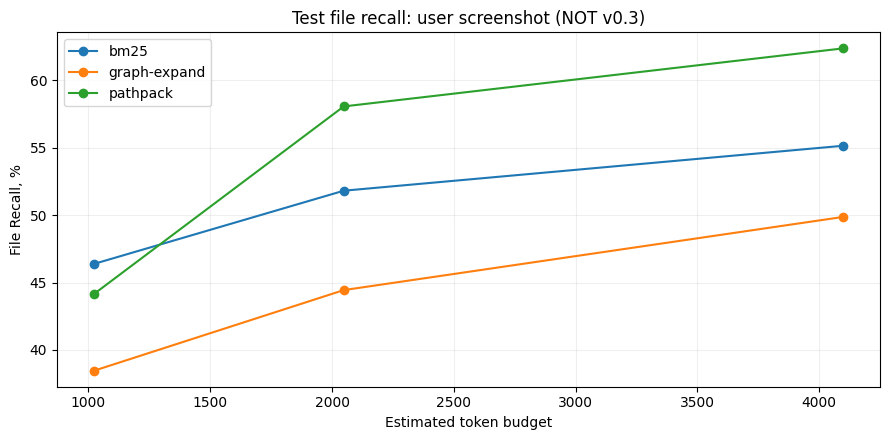

In [3]:
methods=['bm25','graph-expand','pathpack']; budgets=[1024,2048,4096]
fig,ax=plt.subplots(figsize=(9,4.5))
for method in methods:
    y=[100*next(row['file_recall'] for row in rows if row['split']=='test' and row['budget']==b and row['method']==method) for b in budgets]
    ax.plot(budgets,y,marker='o',label=method)
ax.set(title='Test file recall: user screenshot (NOT v0.3)',xlabel='Estimated token budget',ylabel='File Recall, %')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(ROOT/'visualizations'/'user_file_recall.png',dpi=160)
plt.show()


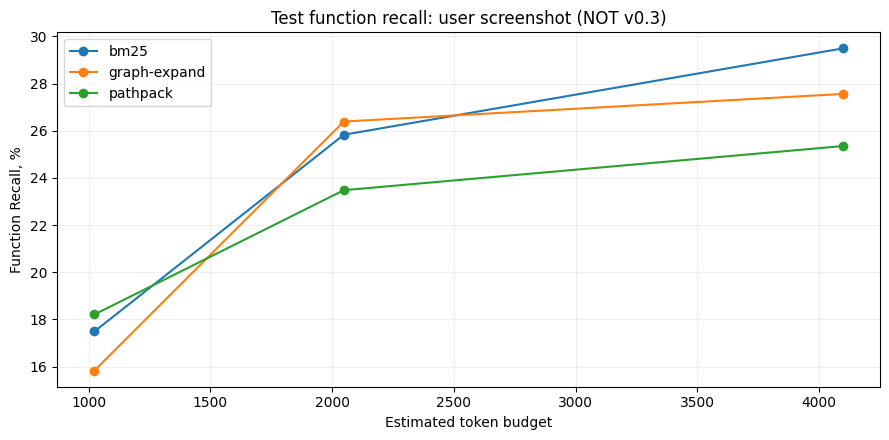

In [4]:
fig,ax=plt.subplots(figsize=(9,4.5))
for method in methods:
    y=[100*next(row['function_recall'] for row in rows if row['split']=='test' and row['budget']==b and row['method']==method) for b in budgets]
    ax.plot(budgets,y,marker='o',label=method)
ax.set(title='Test function recall: user screenshot (NOT v0.3)',xlabel='Estimated token budget',ylabel='Function Recall, %')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(ROOT/'visualizations'/'user_function_recall.png',dpi=160)
plt.show()


## 2. Проверка фиксированного порядка кандидатов в PathPack v0.3

В новой версии ранжирование не зависит от бюджета. Для каждого бюджета берётся префикс списка кандидатов до первого не помещающегося фрагмента, без замены ранее выбранных элементов. **Компромисс:** часть бюджета может остаться пустой.

In [5]:
snapshot=ROOT/'examples'/'issue_demo'/'snapshot'
graph=scan_repository(snapshot)
chunks=make_chunks(snapshot,graph)
query='Login cookie causes failure'
prev=set()
for budget in [45,70,110,160,512]:
    hits=select_context(chunks,graph,query,method='pathpack-v3',budget=budget,seeds=1,hops=2)
    ids={h.chunk.id for h in hits}
    assert prev.issubset(ids), f'Nestedness violated at budget {budget}'
    used=sum(h.chunk.tokens_est for h in hits)
    assert used<=budget
    print(budget, 'used',used,'chunks',[h.chunk.qualname for h in hits])
    prev=ids


45 used 38 chunks ['login_with_cookie']
70 used 38 chunks ['login_with_cookie']
110 used 82 chunks ['login_with_cookie', 'read_session']
160 used 114 chunks ['login_with_cookie', 'read_session', 'login_event_log']
512 used 114 chunks ['login_with_cookie', 'read_session', 'login_event_log']


## 3. Иллюстрация цепочки зависимостей: файл → функция → вызов

Следующий граф построен из AST учебного репозитория. Подсвечен контекст PathPack v0.3 при бюджете 160 (синтетический пример).

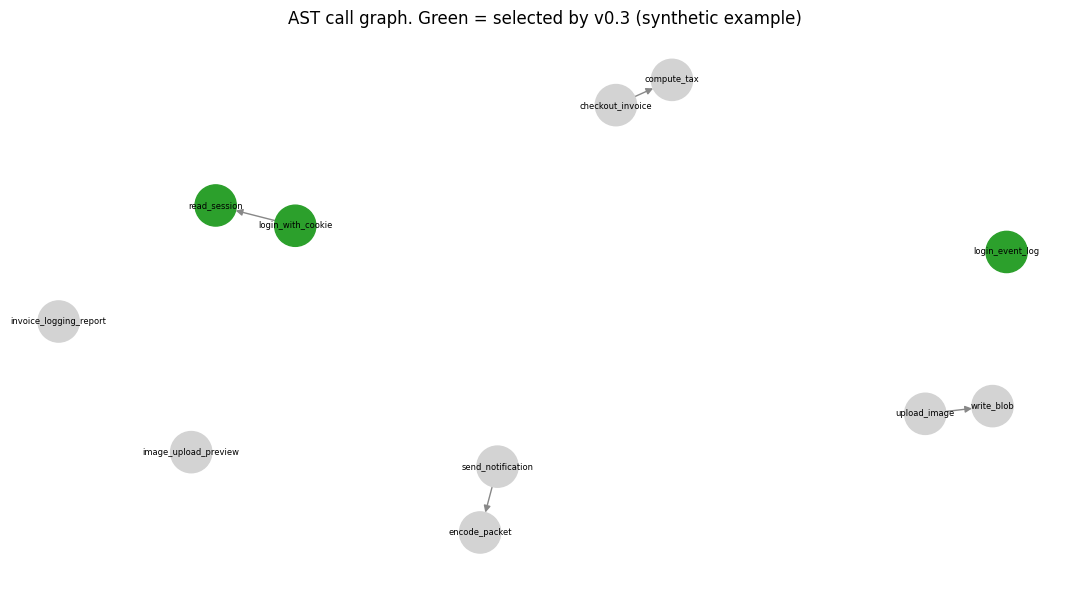

In [6]:
import networkx as nx
G=nx.DiGraph()
for node in graph.nodes.values():
    if node.kind in ('function','method'):
        G.add_node(node.id)
for edge in graph.edges:
    if edge.kind=='calls' and edge.source in G and edge.target in G:
        G.add_edge(edge.source,edge.target)
hits=select_context(chunks,graph,query,method='pathpack-v3',budget=160,seeds=1,hops=2)
selected={h.chunk.id for h in hits}
fig,ax=plt.subplots(figsize=(11,6))
pos=nx.spring_layout(G,seed=24)
node_colors=['tab:green' if n in selected else 'lightgray' for n in G.nodes]
nx.draw_networkx(G,pos=pos,ax=ax,node_color=node_colors,node_size=880,font_size=6,
                 labels={n:n.split('::')[-1] for n in G.nodes},arrows=True,edge_color='#888888')
ax.set_title('AST call graph. Green = selected by v0.3 (synthetic example)');ax.axis('off')
fig.tight_layout()
fig.savefig(ROOT/'visualizations'/'v03_selected_call_graph.png',dpi=170)
plt.show()


## 4. Сравнение на четырёх учебных задачах (не реальный SWE-bench)

Результаты v0.3 могут быть **хуже v0.2**. Это не скрываем, поскольку пока проверяем инженерные свойства и протокол оценки.

In [7]:
toy=json.loads((ROOT/'reports'/'v03_demo'/'audit_demo.json').read_text())
for method in ('bm25','graph-expand','pathpack','pathpack-v3'):
    key=f'{method}@110'
    print(f'{method:13} toy File Recall@110 = {toy["groups"][key]["file_recall"]:.2f}')
print('Nested violations:',len(toy['nested_violations']))


bm25          toy File Recall@110 = 0.00
graph-expand  toy File Recall@110 = 1.00
pathpack      toy File Recall@110 = 1.00
pathpack-v3   toy File Recall@110 = 0.75
Nested violations: 2


## 5. Запуск на твоих настоящих предсказаниях

После подготовки snapshots и `issues.jsonl` из SWE-bench Verified сначала выполни на **dev**:

```bash
bash scripts/run_dev.sh
```

Отчёт `reports/audit_dev.json` покажет случаи, где правильный файл выбран, но функция нет. Для function-level метрик нужна дополнительная gold-разметка, которая формируется **строго отдельно, после выдачи предсказаний**:

```bash
codegraph gold-functions --raw raw_verified.jsonl --snapshots snapshots \
  --gold output/benchmark/gold_labels.jsonl \
  --out output/benchmark/gold_functions.jsonl
codegraph audit --predictions output/v03_dev/*.jsonl \
  --gold output/benchmark/gold_functions.jsonl \
  --out reports/audit_functions_dev.json
```

Сбор патчей не должен попадать в retriever. Просмотренный ранее test набор из 60 задач теперь исследовательски **не полностью закрыт для подстройки**. Для финального результата нужен новый заранее зафиксированный holdout.
